# 11: Which words carry the decision

**DATA 5500, Senior Design**

**Sara Choque Molina**

Q2 asks which words carry the weight in the model's decisions. Notebook 07 answered it with the model's coefficients, which give the weight a word holds on its own. Here we measure how much each word moves the decisions the model actually makes, across the 136 labeled articles.

| File | Contents |
|---|---|
| `training_set.csv` | The 136 labeled articles with text, from notebook 07 |

## Block 1: The model

We fit the model of record on all 136 labeled articles, with the settings and the class weights notebook 09 used, so the explanations describe the model the project reports.

In [1]:
import os
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.utils.class_weight import compute_sample_weight

FOLDER = r"C:\Users\sara_\Desktop\College\DATA 5500-01 Senior Des\data bases"

LABELS = ["targeted_threat", "nontargeted_threat", "unrelated"]

training = pd.read_csv(os.path.join(FOLDER, "training_set.csv"))

model = make_pipeline(
    TfidfVectorizer(stop_words="english", min_df=2),
    LogisticRegression(max_iter=1000),
)

weights = compute_sample_weight("balanced", training["label"])
model.fit(training["text"], training["label"], logisticregression__sample_weight=weights)

vectorizer = model.named_steps["tfidfvectorizer"]
classifier = model.named_steps["logisticregression"]

print("Articles:", len(training))
print("Vocabulary learned:", len(vectorizer.vocabulary_))
print("Classes:", list(classifier.classes_))

Articles: 136
Vocabulary learned: 2488
Classes: ['nontargeted_threat', 'targeted_threat', 'unrelated']


## Block 2: What each word contributes

For a linear model the contribution of a word to one article has a closed form: the word's coefficient times how far that article sits from the average article on that word. Averaging that across the 136 articles gives how much the word moves the decisions the model actually makes.

The table also carries the raw coefficient and its rank, so the two ways of answering Q2 sit side by side.

In [2]:
import numpy as np

X = vectorizer.transform(training["text"]).toarray()
average_article = X.mean(axis=0)
words = np.array(vectorizer.get_feature_names_out())

# Linear SHAP. For a linear model the exact contribution of a word to one article is its
# coefficient times how far that article sits from the average article on that word.
# This is the same value the shap library computes for a linear model, written out.
for position, label in enumerate(classifier.classes_):
    coefficients = classifier.coef_[position]
    contribution = (X - average_article) * coefficients

    # Signed contributions cancel out across articles, so the size of a word's effect is
    # the average push it gives, taken without its direction.
    strength = np.abs(contribution).mean(axis=0)
    coefficient_rank = pd.Series(np.abs(coefficients)).rank(ascending=False, method="min").astype(int)

    order = np.argsort(strength)[::-1][:15]

    print(label)
    print(pd.DataFrame({
        "word": words[order],
        "contribution": strength[order].round(4),
        "coefficient": coefficients[order].round(3),
        "coefficient rank": coefficient_rank.values[order],
    }).to_string(index=False))
    print()

nontargeted_threat
       word  contribution  coefficient  coefficient rank
     tiktok        0.0630        1.256                 1
    threats        0.0538        0.978                 2
    schools        0.0477        0.977                 3
     social        0.0400        0.917                 4
      media        0.0378        0.910                 5
   district        0.0342        0.643                 8
    student        0.0254       -0.460                10
  districts        0.0239        0.729                 6
     friday        0.0167        0.358                22
  challenge        0.0165        0.647                 7
       high        0.0165       -0.403                16
    parents        0.0163        0.433                14
        law        0.0151        0.455                12
enforcement        0.0150        0.461                 9
     middle        0.0124       -0.288                29

targeted_threat
       word  contribution  coefficient  coefficient 

**Results**

- `tiktok` carries the most weight toward `nontargeted_threat`, and the same word pushes away from `targeted_threat`. The model separates the two classes on the vocabulary of the trend against the vocabulary of a named school, where `school`, `middle`, `high` and `police` lead.
- `lockdown` is the one word pushing toward `unrelated`, which matches the codebook: a lockdown with no threat behind it belongs there.
- 40 of the 45 words listed also sit in the top 20 by coefficient, so the two ways of answering Q2 land in the same place. The ones that rise, among them `said`, `social` and `friday`, appear across many articles and gather weight from use rather than from size.

## Block 3: The ten words per class

For each class, the figure shows the ten words with the largest average contribution. Dark bars push an article toward that class and light bars push it away.

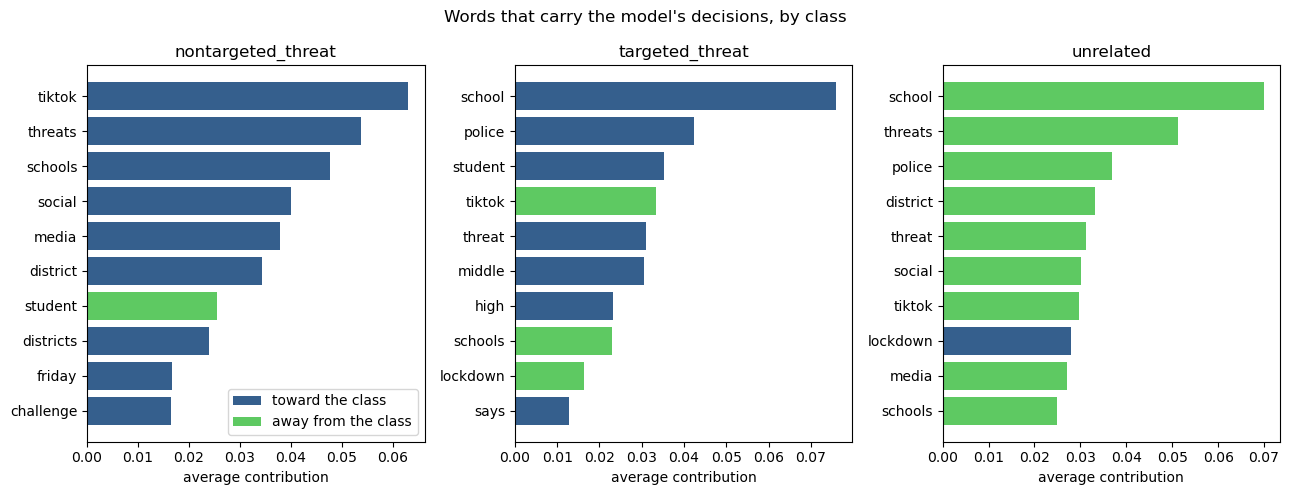

In [3]:
import matplotlib.pyplot as plt

dark, light = plt.cm.viridis(0.3), plt.cm.viridis(0.75)

figure, panels = plt.subplots(1, 3, figsize=(13, 5))

for panel, (position, label) in zip(panels, enumerate(classifier.classes_)):
    coefficients = classifier.coef_[position]
    strength = np.abs((X - average_article) * coefficients).mean(axis=0)

    # Largest at the top, so the order is reversed for a horizontal bar chart.
    order = np.argsort(strength)[::-1][:10][::-1]
    toward = coefficients[order] > 0
    rows = np.arange(len(order))

    panel.barh(rows[toward], strength[order][toward], color=dark, label="toward the class")
    panel.barh(rows[~toward], strength[order][~toward], color=light, label="away from the class")
    panel.set_yticks(rows)
    panel.set_yticklabels(words[order])
    panel.set_title(label)
    panel.set_xlabel("average contribution")

panels[0].legend(loc="lower right")
plt.suptitle("Words that carry the model's decisions, by class")
plt.tight_layout()
plt.savefig(os.path.join(FOLDER, "figures", "11_word_contribution.png"), dpi=200)
plt.show()

**Results**

- `unrelated` is recognized almost entirely by what is missing. Nine of its ten words push away from the class, and `lockdown` is the one that pushes toward it.
- `nontargeted_threat` has a vocabulary of its own, with nine of its ten words pushing toward it: the trend and how it spread, `tiktok`, `social`, `media`, `challenge`.
- The singular and the plural split the two threat classes. `school` leads `targeted_threat`, while `schools` pushes toward `nontargeted_threat` and away from `targeted_threat`. One named school against many, which is the line the codebook draws.

## Conclusions

This notebook answered Q2 with a second method. Notebook 07 read the model's coefficients. Here we measured how much each word moves the decisions the model makes across the 136 labeled articles, using the exact form SHAP takes for a linear model.

The two methods agree. 40 of the 45 top words by contribution also sit in the top 20 by coefficient, so the answer from notebook 07 holds.

The words follow the codebook's own logic. The trend vocabulary, `tiktok`, `social`, `media` and `challenge`, marks threats with no named target. A single named school marks a targeted one, and the singular `school` against the plural `schools` carries that line by itself. Articles that belong to neither class are recognized mostly by the absence of threat vocabulary, with `lockdown` as the one word that points toward them.

**Limits**

- The contributions come from the 136 labeled articles, all from 2021.